In [110]:
import torch 
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [111]:
dataset = pd.read_csv("students_100.csv")
dataset.head()

,student_id,city,study_hours,phone_hours,height_cm,maths,english,science
0,1,Lahore,3.0,3.5,177.0,49.0,61.0,54.0
1,2,Islamabad,3.4,2.7,173.0,71.0,59.0,71.0
2,3,Lahore,2.7,4.2,157.0,56.0,66.0,54.0
3,4,Karachi,1.9,7.4,158.0,39.0,55.0,53.0
4,5,Lahore,2.5,2.8,161.0,69.0,65.0,70.0


In [112]:
# print(dataset[["study_hours" , "phone_hours"]])

x = torch.tensor(dataset[["study_hours" , "phone_hours"]].values ,
                  dtype=torch.float32)

Y = torch.tensor(dataset["maths"].values , 
                 dtype=torch.float32)


print(x.shape )
print(Y.shape )

torch.Size([100, 2])
torch.Size([100])


In [113]:
torch.manual_seed(42)

model = nn.Sequential(
    nn.Linear(2, 4),
    nn.ReLU(),
    nn.Linear(4, 1)
)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)

:epoch   0: loss = 2818.9
:epoch  50: loss = 271.7
:epoch 100: loss = 240.6
:epoch 150: loss = 206.6


c:\Users\Dell\ASHREITECH\Python-for-AI\.venv312\Lib\site-packages\torch\nn\modules\loss.py:630: UserWarning: Using a target size (torch.Size([100])) that is different to the input size (torch.Size([100, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


:epoch 200: loss = 176.2
:epoch 250: loss = 164.0


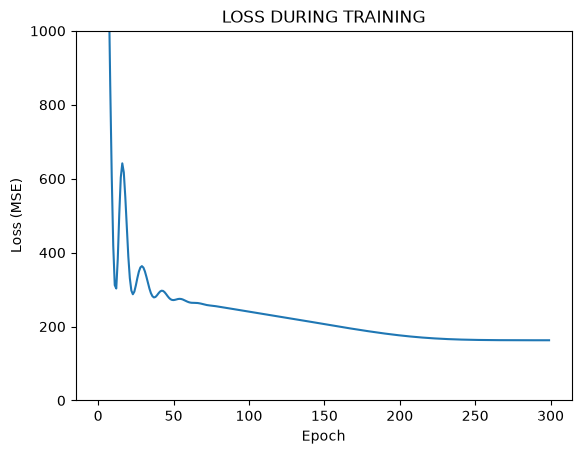

3 study hours, 2 phone hours --> 53.7 marks


In [114]:
losses = []
for epoch in range(300):
    guess = model(x)
    # print(guess)
    loss = loss_fn(guess, Y)
    optimizer.zero_grad()
    loss.backward()

    optimizer.step()
    losses.append(loss.item())
    if epoch % 50 == 0:
        print(f":epoch {epoch:3}: loss = {loss.item():.1f}")


plt.plot(losses)
plt.ylim(0, 1000)
plt.title("LOSS DURING TRAINING")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.show()


with torch.no_grad():
    new_student = torch.tensor([[1, 5]], dtype=torch.float32 )
    print("3 study hours, 2 phone hours -->", round(model(new_student).item(), 1), "marks")